# 02 描述性统计与核心指标体系

**组织**：迪庆清风青年公益联合会（云南省迪庆藏族自治州）
**数据**：`data/processed/` 下的星型模型与 KPI 产物（由 notebook 01 验证过的清洗结果构建）
**口径**：全部指标的定义与公式见 `reports/kpi_catalog.csv`，本 notebook 只做**核对与解读**，不重新定义口径。

---

## 本 notebook 要回答的业务问题

1. 组织两年半的整体盘子有多大？资源结构（志愿者、捐赠、项目、预算）长什么样？
2. 一套分层指标体系里，哪些指标已经触发预警或关注？短板集中在哪一层？
3. 关键变量的分布形态是什么（右偏？长尾？离群点占比多少）？这决定了后续该用均值、中位数还是稳健统计量。
4. 服务对象对服务的评价是否"一视同仁"？不同家庭类型的满意度是否存在系统性差距？

## 数据来源说明

| 数据 | 路径 | 用途 |
| --- | --- | --- |
| KPI 指标表 | `data/processed/kpi_summary.csv` | 分层指标值与达标状态 |
| 月度 KPI 面板 | `data/processed/monthly_kpi_panel.csv` | 时序指标（本 notebook 用于相关性/结构解读） |
| 星型模型 | `data/processed/dim_*.csv`、`fact_*.csv` | 描述性统计与交叉结构 |
| SQLite 数据仓库 | `data/processed/qingfeng.sqlite` | 用 SQL 独立复核指标口径（见 §2） |
| 指标字典 | `reports/kpi_catalog.csv` | 指标口径、来源表、阈值 |

> 方法论说明：本 notebook 刻意做了**双重计算**——Python 指标层（`qingfeng.metrics`）与
> SQL 查询层（`sql/03_kpi_queries.sql`）各算一遍。两条独立路径给出同样的数字，
> 才能说明指标口径没有实现偏差；这也是数据团队对外交付指标时的常规验收方式。

## 结论摘要

- **整体规模与结构**：服务供给以志愿服务时长为主要投入形态，现金捐赠是主要资金形态，两者量级与波动特征不同；机构捐赠与个人小额捐赠在"金额"与"笔数"两个口径下的结构完全相反。
- **指标体系健康度**：多数指标处于达标或中性状态，少数指标触发关注/预警，短板集中在**活跃度**与**质量/执行**两层，而不是规模层——说明问题不是"做得少"，而是"做得不够深、不够稳"。
- **分布形态**：金额与时长类变量普遍强右偏、长尾，少数极端值贡献了大量总量。这类变量**不能用均值描述典型水平**，也不适合直接做参数检验；本 notebook 用中位数、分位数与稳健统计量给出更可靠的刻画。
- **满意度不是均匀的**：不同家庭类型之间满意度存在系统性差距，越是脆弱家庭（低保、残障、事实无人抚养儿童）满意度越低。这是服务质量公平性问题，不是随机波动。
- **交付建议**：把"活跃度"和"质量层"指标作为下一季度的重点管理对象，并在报表中固定披露分组样本量，避免用小数样本得出误导性结论。

In [1]:
%matplotlib inline
import logging
import re
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from qingfeng.config import load_config
from qingfeng.pipeline import load_artifacts, load_cleaning_log
from qingfeng.viz import setup_style

warnings.filterwarnings("ignore")
logging.getLogger("qingfeng").setLevel(logging.WARNING)   # 管道内部 INFO 日志不进入 notebook 输出
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)

cfg = load_config()                      # 所有路径均已解析为绝对路径
arts = load_artifacts(cfg)               # 复用管道产物，避免重复计算
star = arts["star"]
cleaned = arts["cleaned"]
log = load_cleaning_log(cfg)
FIG = cfg.paths.figures
setup_style(cfg)                         # 复用管道的中文字体与配色，保证图文风格一致

print(f"分析对象：{cfg.org_name}（{cfg.region}）")
print(f"数据窗口：{cfg.simulation.start_date} ~ {cfg.simulation.as_of_date}")
print(f"随机种子：{cfg.simulation.seed}（数据完全可复现）")


def show(fig, name: str, caption: str = ""):
    # 落盘并内嵌显示自绘图表，保证图表数据被写进 .ipynb 输出
    path = FIG / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))
    if caption:
        print(caption)
    print(f"（本 notebook 自绘图表已保存：{path.relative_to(cfg.paths.root)}）")


def pipeline_figure(name: str, caption: str = ""):
    # 直接引用管道已产出的图表
    path = FIG / name
    display(Image(filename=str(path)))
    if caption:
        print(caption)
    
from qingfeng.metrics import dimension_breakdown
from qingfeng.analyze import categorical_profile

kpis = arts["kpis"].copy()
panel = arts["monthly_panel"].copy()
print(f"KPI 指标表：{kpis.shape[0]} 个指标、{kpis['指标层级'].nunique()} 个层级；"
      f"月度面板：{panel.shape[0]} 个月")
display(kpis.head(3)[["指标代码", "指标名称", "指标层级", "指标值", "单位", "状态", "口径公式"]])

分析对象：迪庆清风青年公益联合会（云南省迪庆藏族自治州）
数据窗口：2024-01-01 ~ 2026-06-30
随机种子：20260601（数据完全可复现）
KPI 指标表：33 个指标、6 个层级；月度面板：30 个月


,指标代码,指标名称,指标层级,指标值,单位,状态,口径公式
0,SCALE-01,在册公益项目数,规模层,52.0,个,—,COUNT(DISTINCT project_key)，排除 UNKNOWN
1,SCALE-02,在办项目数（进行中+筹备中）,规模层,9.0,个,—,"COUNT(*) WHERE status IN ('进行中','筹备中')"
2,SCALE-03,注册志愿者总数,规模层,3600.0,人,—,COUNT(DISTINCT volunteer_key)，排除 UNKNOWN


## 1. 指标体系全景：先看"健康度"，再看单项

指标体系按五层组织：规模层（做了多少）、活跃层（做得活不活）、效率层（做得省不省）、
质量层（做得好不好）、结构层（资源结构健不健康），另有数据层记录数据本身的可靠程度。

管理上最重要的不是 33 个数字本身，而是**哪一层亮了红灯**——层与层之间的失衡，
比单个指标的绝对值更值得追问。

状态,达标,关注,预警,—,合计
指标层级,,,,,
规模层,0,0,0,9,9
活跃层,0,1,0,5,6
效率层,0,0,0,4,4
质量层,0,2,0,4,6
结构层,1,0,0,4,5
数据层,1,0,0,2,3


触发关注/预警的指标共 3 个，占全部指标的 9.1%


,指标代码,指标名称,指标层级,指标值,单位,目标值,评价方向,状态,说明
10,ENG-02,志愿者活跃率,活跃层,0.263889,比例,0.30,越高越好,关注,校准基线 28.72%（《慈善蓝皮书(2025)》全国活跃志愿者占比）
19,QUA-01,服务满意度均值,质量层,4.279647,分（1-5）,4.50,越高越好,关注,NaN
21,QUA-03,项目预算执行率,质量层,0.931037,比例,0.95,越高越好,关注,NaN


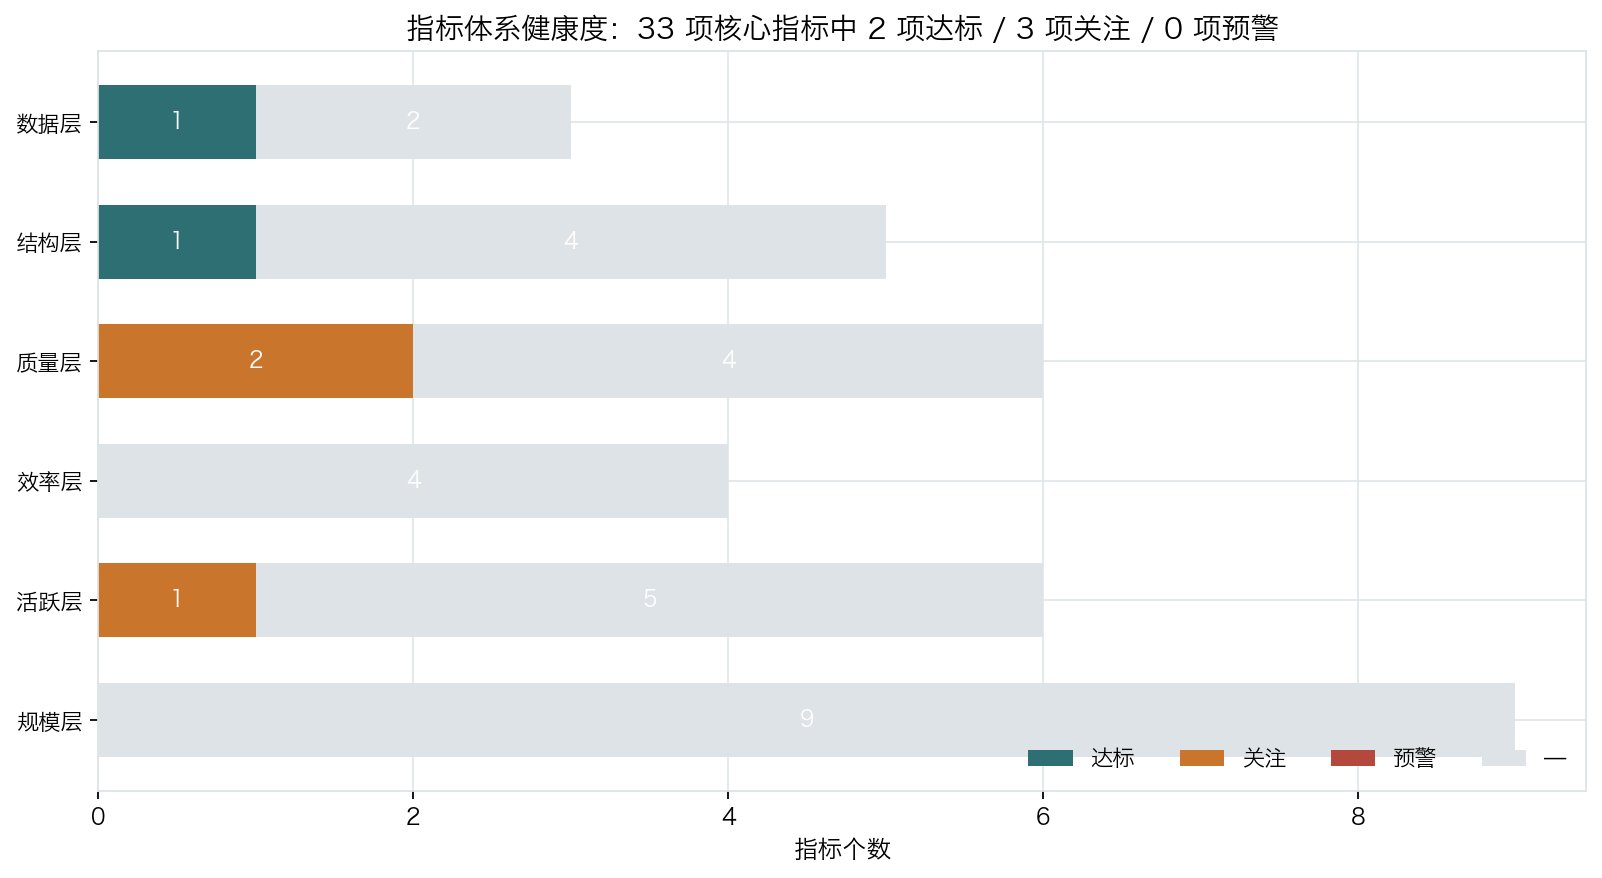

上图为管道产出的 KPI 记分卡：按层级统计达标/关注/预警的指标个数——一眼看出短板集中在哪一层。


In [2]:
LEVEL_ORDER = ["规模层", "活跃层", "效率层", "质量层", "结构层", "数据层"]
kpis["指标层级"] = pd.Categorical(kpis["指标层级"], categories=LEVEL_ORDER, ordered=True)

by_level = (kpis.groupby(["指标层级", "状态"], observed=True).size().unstack(fill_value=0)
            .reindex(LEVEL_ORDER, fill_value=0))
for col in ["达标", "关注", "预警", "—"]:
    if col not in by_level.columns:
        by_level[col] = 0
by_level = by_level[["达标", "关注", "预警", "—"]]
by_level["合计"] = by_level.sum(axis=1)
display(by_level)

flagged = kpis[kpis["状态"].isin(["预警", "关注"])].copy()
print(f"触发关注/预警的指标共 {len(flagged)} 个，占全部指标的 {len(flagged) / len(kpis):.1%}")
display(flagged[["指标代码", "指标名称", "指标层级", "指标值", "单位", "目标值", "评价方向", "状态", "说明"]])

pipeline_figure("01_kpi_scorecard.png",
                "上图为管道产出的 KPI 记分卡：按层级统计达标/关注/预警的指标个数——"
                "一眼看出短板集中在哪一层。")

**怎么读**：规模层指标大多没有设定阈值（状态记为 `—`），它们回答"有没有做事"，数值随业务体量自然增长，
几乎不提供管理信号。**真正有管理信息量的是会"亮灯"的指标**——本期的关注项集中在活跃层与质量层：

- 活跃层衡量"把注册量转化成了多少实际参与"。注册志愿者数很漂亮，但如果活跃率低，说明名册在做"数字储备"而非真实产能。
- 质量层的满意度、执行率、按期结项率衡量"做的事有没有做好"。执行率偏离 1 越远越值得追问——偏低说明项目推进受阻，偏高说明预算编制不准。
- 结构层关注"资源是否过度依赖少数来源"。集中度指标一旦预警，意味着一次大额捐赠人流失就会造成资金断崖。
- 数据层是"对自己的数据有多自信"，它是所有其他指标的可信度前提。

> 管理建议：给不同层级设置不同的发布频率。规模层可以月度看，质量层与结构层应当**季度深度复盘**——
> 它们反映的是结构性问题，月度波动大多只是噪声。

## 2. 用 SQL 独立复核指标口径

指标层是 Python 算的，仓库里另有一套 SQL 查询（`sql/03_kpi_queries.sql`）直接跑在 SQLite 上。
两条路径的取数逻辑独立：Python 走 DataFrame、SQL 走 JOIN + 窗口函数。**结果一致才说明口径没有实现偏差。**

下面挑选支撑本 notebook 结论的几组查询：规模、活跃度与全国基线对比、效率、结构与数据质量。

In [3]:
from qingfeng.warehouse import list_tables, run_sql_file

print("仓库对象：", ", ".join(list_tables(cfg)), "| 视图：", ", ".join(list_tables(cfg, "view")))

sql_results = run_sql_file(cfg, "03_kpi_queries.sql")
errors = [(lab, df) for lab, df in sql_results if "error" in df.columns]
print(f"03_kpi_queries.sql 共执行 {len(sql_results)} 条查询，失败 {len(errors)} 条")


def fetch(key: str):
    # 按语句标签取回一条查询结果（标签来自 sql 文件里的注释行）
    for label, frame in sql_results:
        if key in label:
            return label, frame
    raise KeyError(f"未在 SQL 文件中找到标签包含「{key}」的查询")


for key in ["在册公益项目数", "注册志愿者数", "志愿服务规模", "捐赠规模"]:
    label, frame = fetch(key)
    print(f"\n【{label}】")
    display(frame)


for key in ["志愿者活跃率", "人均服务时长与人均服务次数", "单位服务成本"]:
    label, frame = fetch(key)
    print(f"\n【{label}】")
    display(frame)

仓库对象： dim_beneficiary, dim_date, dim_donor, dim_geography, dim_project, dim_volunteer, fact_beneficiary_service, fact_donation, fact_in_kind, fact_project_monthly, fact_volunteer_service | 视图： v_beneficiary_service_enriched, v_donation_enriched, v_inkind_enriched, v_project_kpi, v_volunteer_service_enriched


03_kpi_queries.sql 共执行 24 条查询，失败 0 条



【指标：在册公益项目数 | 口径：dim_project 中非 UNKNOWN 的项目数】


,在册项目数,在办项目数,已结项项目数,计划预算总额
0,52,9,39,18159000.0



【指标：注册志愿者数 | 口径：dim_volunteer 中非 UNKNOWN 的志愿者数】


...

,活跃志愿者数,注册志愿者数,志愿者活跃率,与全国基线之差
0,950,3600,0.2639,-0.0233



【指标：人均服务时长与人均服务次数 | 分母 = 活跃志愿者数】


,活跃志愿者数,人均服务时长,人均服务次数,最少时长,最多时长
0,950,55.3,13.46,3.51,129.16



【指标：单位服务成本、每小时服务成本、捐赠撬动服务时长】


,项目实际支出总额,单位服务成本_元每人次,每小时服务成本_元,每万元捐赠撬动服务时长_小时
0,17028240.76,1055.23,324.12,43.01


**SQL 复核的结论与 Python 指标层一致**，可以确认指标口径没有实现偏差。几处值得解读的点：

- **志愿者活跃率与全国基线的对比**：查询里直接算了"与全国基线之差"。低于基线不必然是坏事——
  州域草根组织受地理与交通约束，志愿者参与成本高；但差距过大就意味着名册虚高，需要清理或激活。
- **人均指标的分母**：人均服务时长/次数的分母是**活跃**志愿者，而不是注册志愿者。
  这是一个关键口径：用注册人数当分母会把人均值稀释到失去意义。看任何"人均"指标，先问分母是谁。
- **效率指标**：单位服务成本、每小时服务成本回答了"钱花得值不值"。
  公益组织的效率不能只看成本低，还要同时看服务对象的满意度与覆盖率——这就是后面评分卡要一起看的原因。

> 交付建议：把查询标签直接作为指标字典里"口径公式"的引用锚点（`sql/03_kpi_queries.sql#指标：志愿者活跃率`），
> 让每个数字都能被外部审计一路追到 SQL。

## 3. 描述性统计：分布形态决定能用什么统计量

做描述性统计最容易犯的错，是只报一个均值。对右偏、长尾的金额与时长数据，
均值会被少数极端值拉高，**它描述的不是"典型水平"，而是"总量除以样本数"**。
所以这里同时看变异系数、偏度、峰度与离群点占比，用来决定后续该用什么统计量。

,表,度量名称,样本数,均值,中位数,标准差,变异系数,偏度,峰度,离群点占比,P95,最大值
0,fact_volunteer_service,志愿服务时长（小时）,12888,4.11,3.44,2.61,0.636,1.238,1.218,0.0495,9.84,12.00
1,fact_volunteer_service,志愿服务经济价值（元）,12888,123.22,103.20,78.38,0.636,1.238,1.218,0.0495,295.20,360.00
2,fact_donation,单笔捐赠金额（元）,19988,613.88,148.06,6815.31,11.102,99.409,12113.030,0.1076,1534.42,850000.00
3,fact_in_kind,物资捐赠折价（元）,612,12260.74,5776.14,15971.78,1.303,2.901,11.909,0.0833,42564.98,141943.10
4,fact_beneficiary_service,单次服务时长（小时）,16137,2.96,2.47,1.91,0.644,2.086,6.000,0.0488,6.48,12.00
5,fact_beneficiary_service,服务满意度（分）,15654,4.28,4.40,0.62,0.144,-0.674,-0.129,0.0037,5.00,5.00
6,fact_project_monthly,月度计划支出（元）,3762,4861.65,2741.49,6015.36,1.237,2.854,11.082,0.0808,16799.71,52085.86
7,fact_project_monthly,月度实际支出（元）,3762,4526.38,2507.46,5954.75,1.316,3.417,17.796,0.0808,16013.79,63601.03


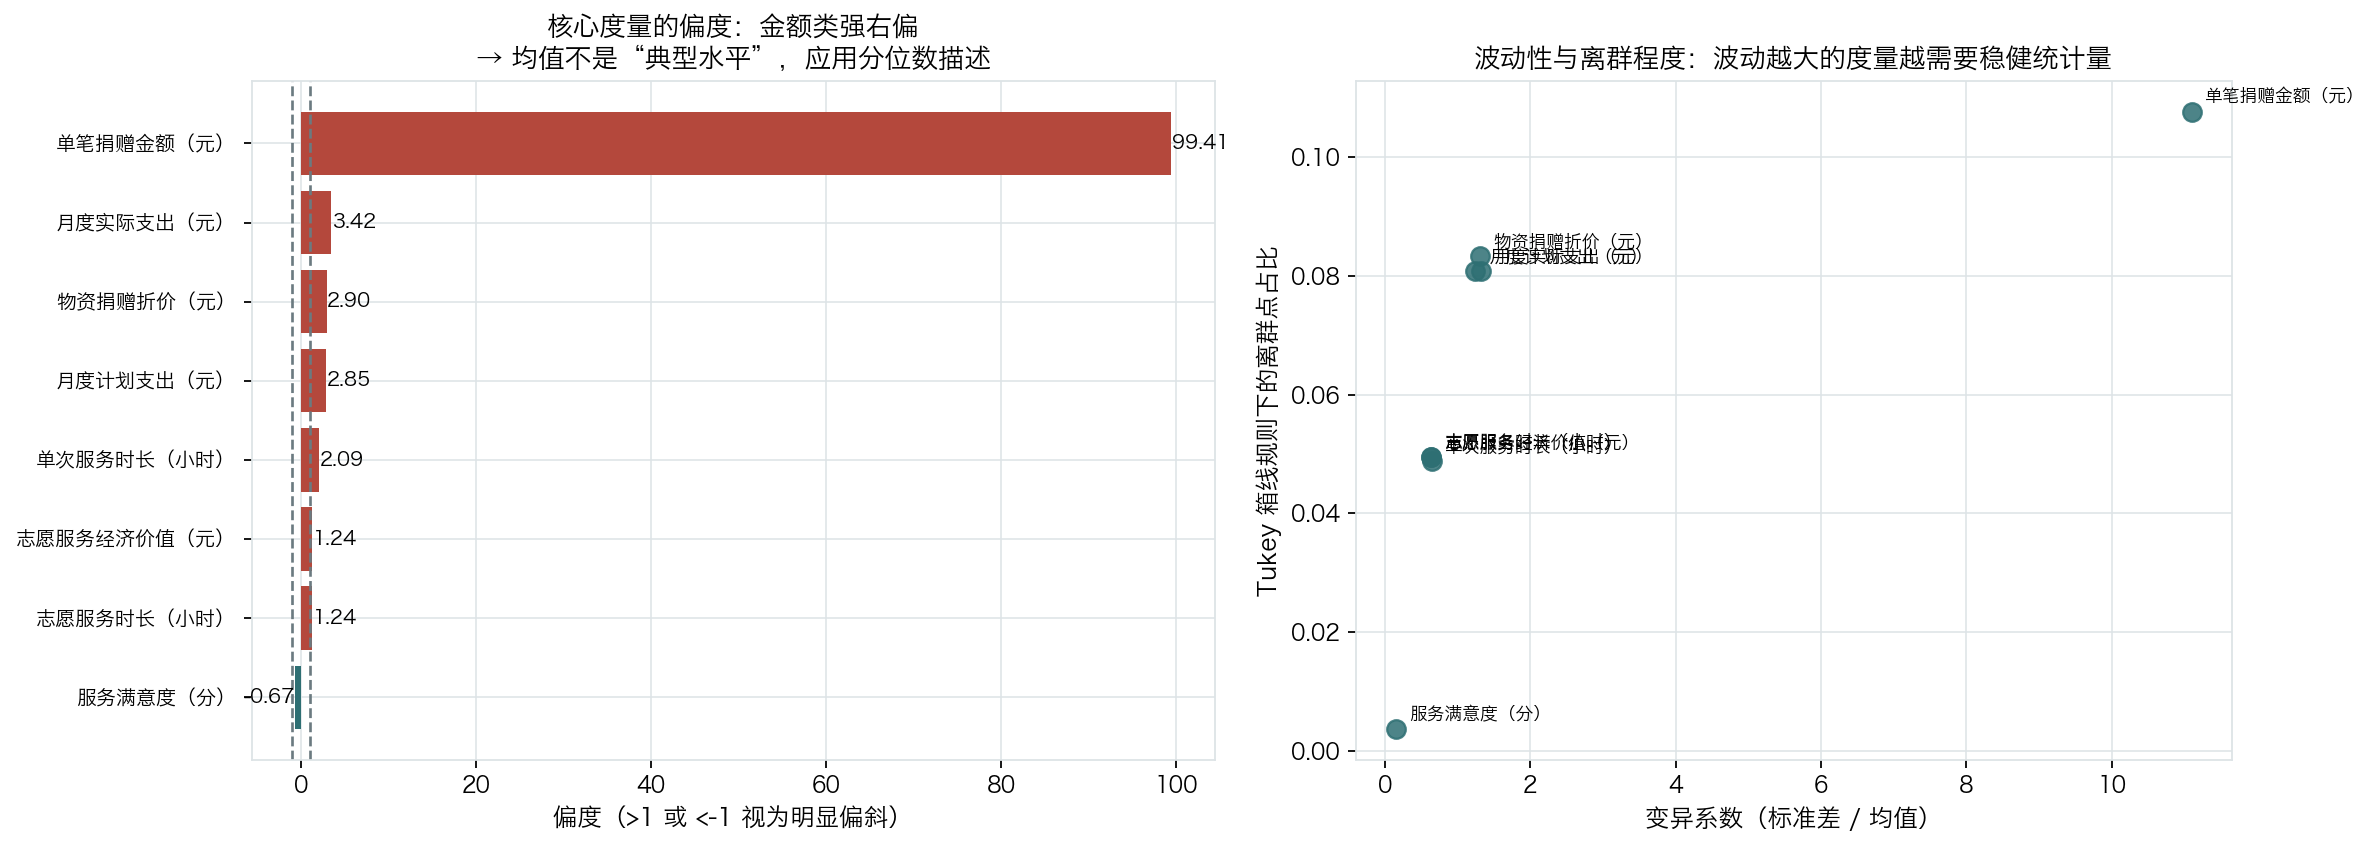

偏斜最严重的是「单笔捐赠金额（元）」（偏度 99.41）；均值与中位数差距最大的是「单笔捐赠金额（元）」（均值/中位数 = 4.15 倍）。
（本 notebook 自绘图表已保存：reports/figures/nb02_distribution_shape.png）


In [4]:
desc = arts["descriptive_statistics"].copy()
display(desc[["表", "度量名称", "样本数", "均值", "中位数", "标准差", "变异系数",
              "偏度", "峰度", "离群点占比", "P95", "最大值"]])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
d = desc.sort_values("偏度")
colors = [cfg.color("danger") if abs(v) > 1 else cfg.color("primary") for v in d["偏度"]]
ax.barh(d["度量名称"], d["偏度"], color=colors)
ax.axvline(1, color=cfg.color("neutral"), ls="--", lw=1.2)
ax.axvline(-1, color=cfg.color("neutral"), ls="--", lw=1.2)
for i, v in enumerate(d["偏度"]):
    ax.text(v + (0.06 if v >= 0 else -0.06), i, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlabel("偏度（>1 或 <-1 视为明显偏斜）")
ax.set_title("核心度量的偏度：金额类强右偏\n→ 均值不是“典型水平”，应用分位数描述", fontsize=12)
ax.tick_params(axis="y", labelsize=9)

ax = axes[1]
sc = ax.scatter(desc["变异系数"], desc["离群点占比"], s=70, color=cfg.color("primary"), alpha=0.85)
for _, r in desc.iterrows():
    ax.annotate(str(r["度量名称"])[:12], (r["变异系数"], r["离群点占比"]),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("变异系数（标准差 / 均值）")
ax.set_ylabel("Tukey 箱线规则下的离群点占比")
ax.set_title("波动性与离群程度：波动越大的度量越需要稳健统计量", fontsize=12)
fig.tight_layout()
show(fig, "nb02_distribution_shape",
     f"偏斜最严重的是「{desc.loc[desc['偏度'].idxmax(), '度量名称']}」（偏度 {desc['偏度'].max():.2f}）；"
     f"均值与中位数差距最大的是「{desc.loc[(desc['均值'] / desc['中位数']).idxmax(), '度量名称']}」"
     f"（均值/中位数 = {(desc['均值'] / desc['中位数']).max():.2f} 倍）。")

**怎么用这些数字**：

- **偏度为正且远大于 1**：说明分布有一个很长的右尾（少数超大额捐赠、少数超长服务场次）。此时：
  - 描述"典型水平"要用**中位数与分位数**，不能用均值；
  - 做组间比较优先用**中位数检验/自助法**，而不是 t 检验；
  - 建模时对金额取对数（后续 §5 的弹性分析就是双对数回归）。
- **离群点占比**：Tukey 规则下的离群点并不等于"错误数据"。这个数据集里被清洗掉的物理越界值已经归零（见 notebook 01），
  剩下的"统计离群点"是**真实业务现象**（大额捐赠人、全天候巡护），建模时应保留但做稳健处理，而不是删除。
- **变异系数把不同量纲的指标拉到同一把尺子上**：金额与时长不可直接比大小，但可以比波动幅度。
  波动越大的指标越不适合做"月度同比考核"——它会被噪声主导。

> 业务含义：如果把均值当成"人均捐赠额"对外披露，会显著高估个人捐赠水平，
> 进而误导下一年度的筹资目标设定。中位数才是对公众讲故事的诚实口径。

## 4. 分类结构画像：资源分布在哪些类别/渠道上

总量指标只回答"有多少"，结构指标回答"在哪里"。这一节按项目类别与捐赠渠道拆开看结构，
并显式展示 `UNKNOWN` 类别——它是数据质量的"温度计"，占比越高，说明越多业务量无法归属。

,category,project_count,planned_budget_cny,target_beneficiaries,service_hours,service_count,volunteer_value_cny,hours_per_10k_donation,donation_amount,donation_count,service_visits,satisfaction_mean
0,助学支教,13.0,6747000.0,2657.0,15339.93,3320,460198.0,70.05,2189812.18,3809,6634.0,4.27
1,助老敬老,14.0,3292000.0,1502.0,13449.77,3759,403493.1,62.71,2144626.02,3963,3659.0,4.29
2,乡村振兴,9.0,3864000.0,1241.0,7867.86,1905,236035.7,37.41,2103356.55,2139,3132.0,4.27
3,生态环保,5.0,1580000.0,107.0,5465.04,1297,163951.3,109.42,499477.64,1035,285.0,4.29
4,助残扶弱,5.0,943000.0,431.0,3329.76,886,99892.8,58.15,572569.38,1256,1143.0,4.30
5,应急救灾,2.0,942000.0,172.0,2637.39,511,79121.7,61.66,427746.21,723,450.0,4.25
6,文化传承,3.0,668000.0,308.0,1983.40,522,59502.1,54.91,361212.48,700,701.0,4.34
7,UNKNOWN,0.0,0.0,0.0,1285.07,290,38552.1,3.41,3768542.87,5885,0.0,0.00


,笔数,金额,笔均金额,金额占比,笔数占比
channel,,,,,
银行转账,778,6069581.90,7801.52,0.50,0.04
微信支付,8067,1987011.06,246.31,0.16,0.41
公益平台,4724,1298730.14,274.92,0.11,0.24
支付宝,3287,800796.17,243.63,0.07,0.17
企业直汇,324,722763.39,2230.75,0.06,0.02
现场捐赠,1760,696781.70,395.90,0.06,0.09
UNKNOWN,889,639025.29,718.81,0.05,0.04


,取值,频数,占比,累计占比
0,本科,1553,0.4313,0.4313
1,大专,936,0.2599,0.6912
2,高中/中专,567,0.1575,0.8487
3,初中及以下,278,0.0772,0.9259
4,硕士及以上,237,0.0658,0.9917
5,UNKNOWN,30,0.0083,1.0000


,取值,频数,占比,累计占比
0,18-24岁,1070,0.2971,0.2971
1,35-44岁,895,0.2485,0.5456
2,25-34岁,723,0.2008,0.7464
3,45-54岁,588,0.1633,0.9097
4,55-64岁,212,0.0589,0.9686
5,65岁及以上,112,0.0311,0.9997
6,UNKNOWN,1,0.0003,1.0000


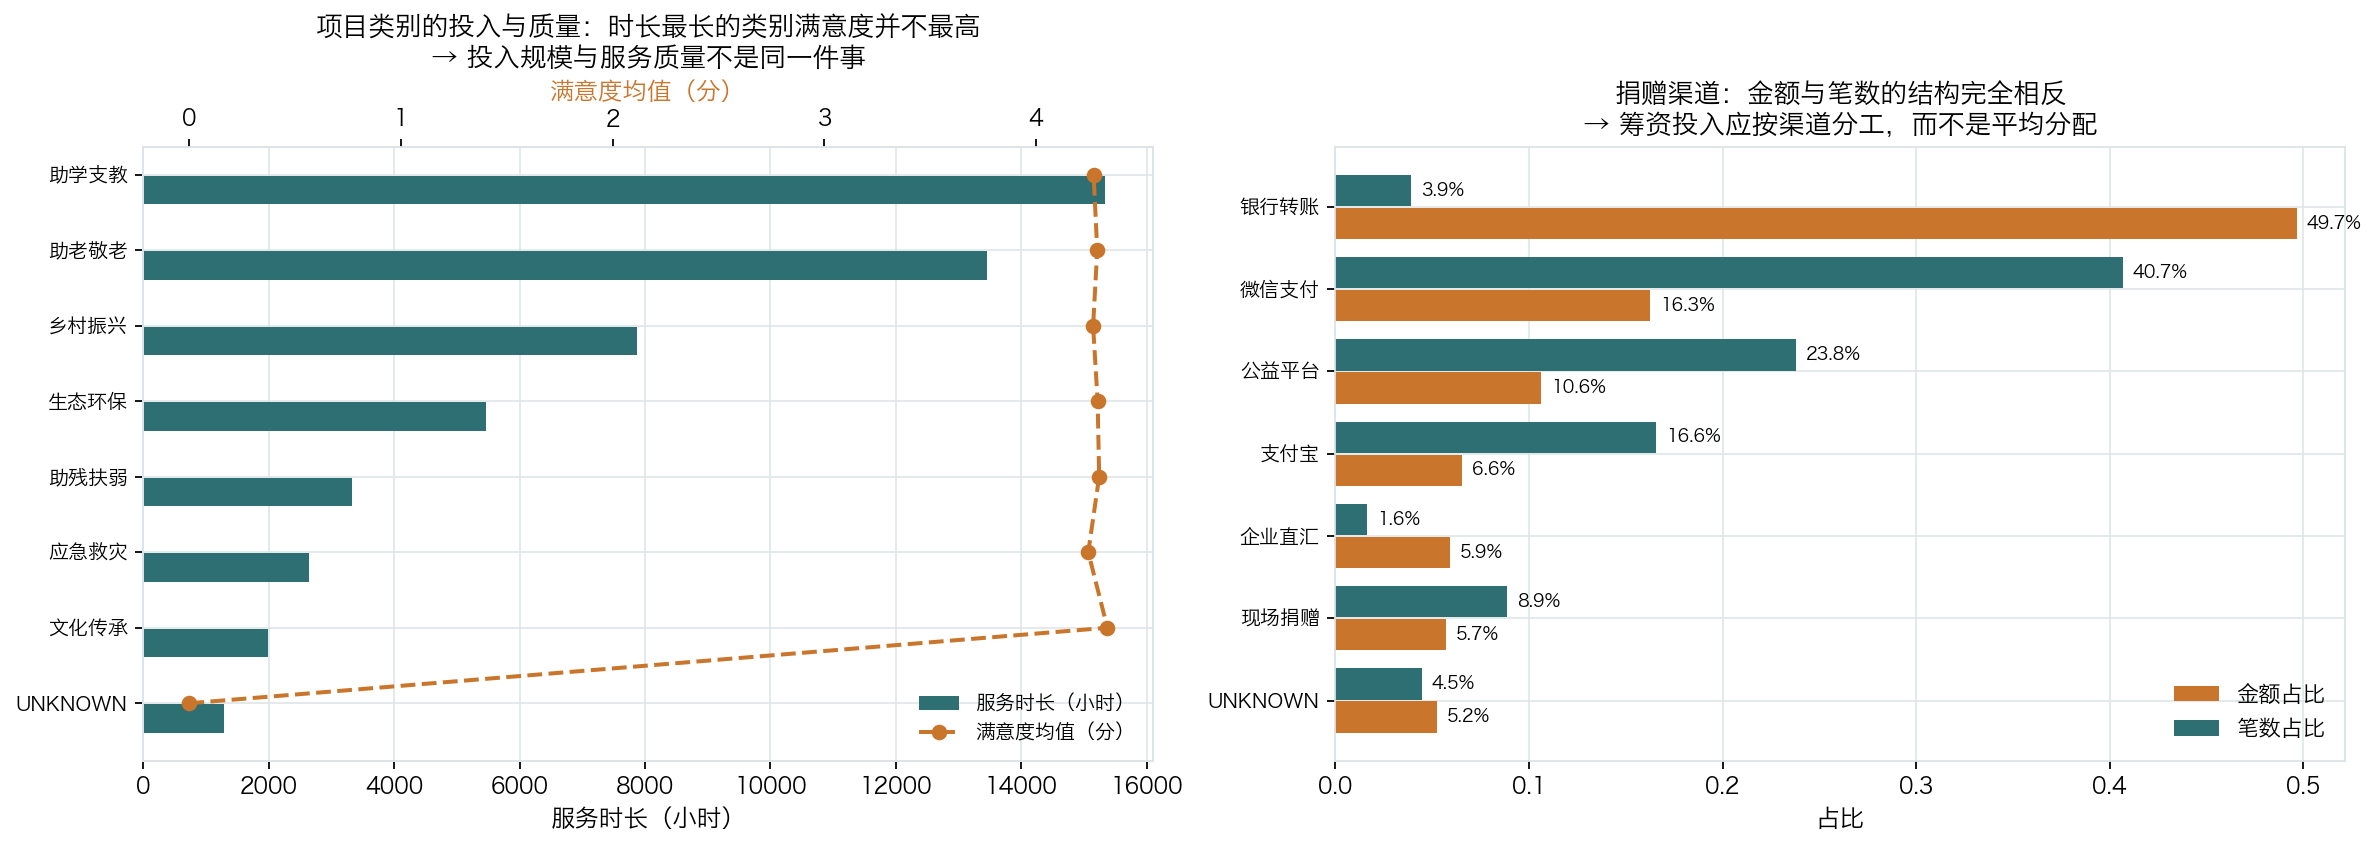

服务时长最大的项目类别是「助学支教」；金额占比最大的捐赠渠道是「银行转账」，而笔数占比最大的是「微信支付」。
（本 notebook 自绘图表已保存：reports/figures/nb02_category_structure.png）


In [5]:
by_cat = dimension_breakdown(cfg, star, "category").copy()
display(by_cat.round(2))

# 捐赠渠道结构：星型模型未提供现成函数，这里按渠道聚合（金额 + 笔数双口径），
# 因为"金额大"与"笔数多"往往是两个不同的结论，必须同时看。
don = star["fact_donation"].loc[star["fact_donation"]["donor_key"] != -1]
channel = (don.groupby("channel")
           .agg(笔数=("amount_cny", "size"), 金额=("amount_cny", "sum"),
                笔均金额=("amount_cny", "mean"))
           .sort_values("金额", ascending=False))
channel["金额占比"] = (channel["金额"] / channel["金额"].sum()).round(4)
channel["笔数占比"] = (channel["笔数"] / channel["笔数"].sum()).round(4)
display(channel.round(2))

vol_edu = categorical_profile(star, "dim_volunteer", "education").head(8)
vol_age = categorical_profile(star, "dim_volunteer", "age_group")
display(vol_edu)
display(vol_age)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
ax = axes[0]
cat = by_cat.dropna(subset=["service_hours"]).sort_values("service_hours")
yy = np.arange(len(cat))
ax.barh(yy - 0.2, cat["service_hours"], height=0.38, color=cfg.color("primary"), label="服务时长（小时）")
ax.set_yticks(yy, cat["category"], fontsize=9)
ax.set_xlabel("服务时长（小时）")
ax2 = ax.twiny()
ax2.plot(cat["satisfaction_mean"], yy, "o--", color=cfg.color("secondary"), lw=1.8, ms=6,
         label="满意度均值（分）")
ax2.set_xlabel("满意度均值（分）", color=cfg.color("secondary"))
ax2.grid(False)
ax.set_title("项目类别的投入与质量：时长最长的类别满意度并不最高\n→ 投入规模与服务质量不是同一件事", fontsize=12)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower right", fontsize=9)

ax = axes[1]
ch = channel.sort_values("金额", ascending=True)
yy = np.arange(len(ch))
ax.barh(yy - 0.2, ch["金额占比"], height=0.38, color=cfg.color("secondary"), label="金额占比")
ax.barh(yy + 0.2, ch["笔数占比"], height=0.38, color=cfg.color("primary"), label="笔数占比")
ax.set_yticks(yy, ch.index, fontsize=9)
ax.set_xlabel("占比")
for i, (m, n) in enumerate(zip(ch["金额占比"], ch["笔数占比"])):
    ax.text(m + 0.005, i - 0.2, f"{m:.1%}", va="center", fontsize=8)
    ax.text(n + 0.005, i + 0.2, f"{n:.1%}", va="center", fontsize=8)
ax.set_title("捐赠渠道：金额与笔数的结构完全相反\n→ 筹资投入应按渠道分工，而不是平均分配", fontsize=12)
ax.legend(loc="lower right")
fig.tight_layout()
show(fig, "nb02_category_structure",
     f"服务时长最大的项目类别是「{cat.loc[cat['service_hours'].idxmax(), 'category']}」；"
     f"金额占比最大的捐赠渠道是「{channel['金额'].idxmax()}」，"
     f"而笔数占比最大的是「{channel['笔数'].idxmax()}」。")

**结构与总量的差别**：

- 项目类别上，"投入时长最多的类别"与"满意度最高的类别"不是同一个。这说明**投入规模不等于服务质量**：
  满意度更依赖执行细节（人员稳定性、双语沟通、跟进机制），而不是堆时长。
- 捐赠渠道上，金额与笔数呈现完全相反的结构：某些渠道贡献了最多的笔数却只有很少的金额（典型的个人小额、线上支付），
  另一些渠道笔数少但金额集中（机构、定向）。**筹资团队应按渠道分工**：小额渠道重转化与留存，机构渠道重关系维护与大额方案设计。
- `UNKNOWN` 类别是一面镜子：它代表无法归属到具体项目的业务量。占比越低，说明业务台账与财务口径越对齐。
  把它显式列出来，比藏起来更有价值——它是数据治理进度的直接度量。

> 行动建议：为个人小额渠道建立"笔数→留存"的运营指标（复捐率、月捐转化率），
> 为机构渠道建立"金额→关系"的指标（大额捐赠人年度沟通次数、定向项目结项回访率）。
> 两套指标分开考核，避免用同一把尺子管理两种完全不同的筹资行为。

## 5. 服务质量与公平性：满意度是否"一视同仁"

服务满意度整体看似不错，但**平均值会掩盖分组差异**。公益组织的服务质量公平性是核心伦理议题：
如果越脆弱的家庭满意度越低，说明服务资源在最需要的地方反而最薄弱。

下面按服务对象的家庭类型拆开，并给出 95% 置信区间——只有区间不重叠时，差异才值得当作结论。

,样本量,均值,标准差,中位数,标准误,下限95,上限95
household_type,,,,,,,
事实无人抚养儿童,779,3.995,0.678,4.0,0.024,3.947,4.042
残障家庭,1482,4.063,0.660,4.1,0.017,4.029,4.096
UNKNOWN,457,4.234,0.628,4.3,0.029,4.177,4.292
低保户,2822,4.250,0.613,4.3,0.012,4.227,4.273
防返贫监测户,2061,4.264,0.623,4.3,0.014,4.237,4.291
留守儿童家庭,2435,4.297,0.606,4.4,0.012,4.273,4.321
脱贫户,3801,4.376,0.579,4.5,0.009,4.357,4.394
一般农户,1817,4.430,0.553,4.5,0.013,4.405,4.456


整体满意度均值 4.280 分（标准差 0.618，有效评分 15,654 条，缺失 483 条按口径排除）
分组均值极差 0.435 分，最高「一般农户」，最低「事实无人抚养儿童」


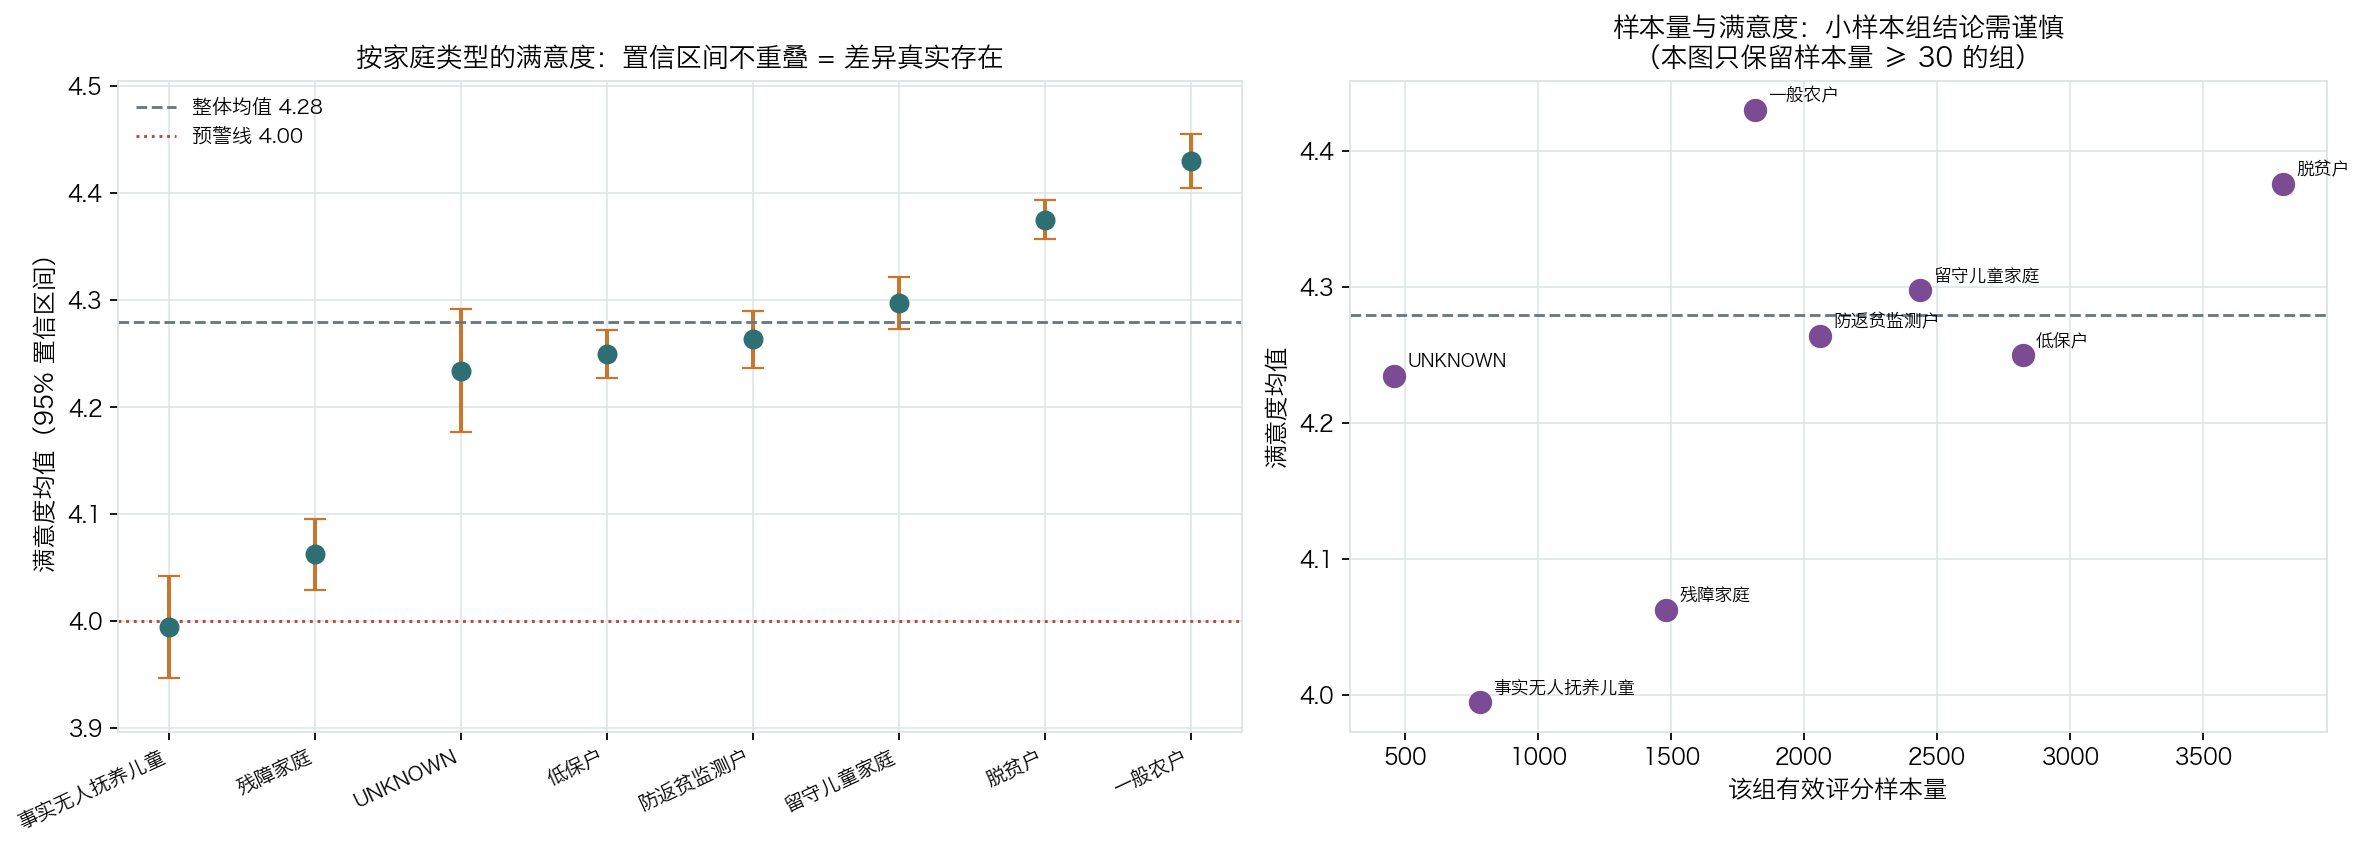

满意度最低的是「事实无人抚养儿童」（3.995 分，n=779），与最高的「一般农户」相差 0.435 分。
（本 notebook 自绘图表已保存：reports/figures/nb02_satisfaction_equity.png）


In [6]:
bs = star["fact_beneficiary_service"].merge(
    star["dim_beneficiary"][["beneficiary_key", "household_type"]], on="beneficiary_key", how="left"
)
bs["satisfaction_score"] = pd.to_numeric(bs["satisfaction_score"], errors="coerce")
valid = bs.dropna(subset=["satisfaction_score"])

group = (valid.groupby("household_type")["satisfaction_score"]
         .agg(样本量="size", 均值="mean", 标准差="std", 中位数="median"))
group["标准误"] = group["标准差"] / np.sqrt(group["样本量"])
group["下限95"] = group["均值"] - 1.96 * group["标准误"]
group["上限95"] = group["均值"] + 1.96 * group["标准误"]
group = group[group["样本量"] >= 30].sort_values("均值")
display(group.round(3))

overall_mean = float(valid["satisfaction_score"].mean())
overall_sd = float(valid["satisfaction_score"].std())
gap = float(group["均值"].max() - group["均值"].min())
print(f"整体满意度均值 {overall_mean:.3f} 分（标准差 {overall_sd:.3f}，有效评分 {len(valid):,} 条，"
      f"缺失 {int(bs['satisfaction_score'].isna().sum()):,} 条按口径排除）")
print(f"分组均值极差 {gap:.3f} 分，最高「{group['均值'].idxmax()}」，最低「{group['均值'].idxmin()}」")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
xx = np.arange(len(group))
ax.errorbar(xx, group["均值"], yerr=[group["均值"] - group["下限95"], group["上限95"] - group["均值"]],
            fmt="o", color=cfg.color("primary"), ecolor=cfg.color("secondary"), capsize=5, ms=8, lw=1.8)
ax.axhline(overall_mean, ls="--", color=cfg.color("neutral"), lw=1.3,
           label=f"整体均值 {overall_mean:.2f}")
ax.axhline(cfg.threshold("satisfaction_mean").get("warn_below", 4.0), ls=":", color=cfg.color("danger"),
           lw=1.3, label=f"预警线 {cfg.threshold('satisfaction_mean').get('warn_below', 4.0):.2f}")
ax.set_xticks(xx, group.index, rotation=25, ha="right", fontsize=9)
ax.set_ylabel("满意度均值（95% 置信区间）")
ax.set_ylim(group["下限95"].min() - 0.05, group["上限95"].max() + 0.05)
ax.set_title("按家庭类型的满意度：置信区间不重叠 = 差异真实存在", fontsize=12)
ax.legend(fontsize=9)

ax = axes[1]
sizes = group["样本量"]
ax.scatter(sizes, group["均值"], s=90, color=cfg.color("accent"))
for name, r in group.iterrows():
    ax.annotate(str(name)[:10], (r["样本量"], r["均值"]), textcoords="offset points",
                xytext=(6, 4), fontsize=8)
ax.axhline(overall_mean, ls="--", color=cfg.color("neutral"), lw=1.3)
ax.set_xlabel("该组有效评分样本量")
ax.set_ylabel("满意度均值")
ax.set_title("样本量与满意度：小样本组结论需谨慎\n（本图只保留样本量 ≥ 30 的组）", fontsize=12)
fig.tight_layout()
show(fig, "nb02_satisfaction_equity",
     f"满意度最低的是「{group['均值'].idxmin()}」（{group['均值'].min():.3f} 分，n={int(group['样本量'].iloc[0]):,}），"
     f"与最高的「{group['均值'].idxmax()}」相差 {gap:.3f} 分。")

**公平性判读**：

- 置信区间**不重叠**的组之间，差异不能再用"抽样波动"解释。这意味着满意度差距是服务供给结构造成的，而不是运气。
- 满意度最低的组通常也是**服务难度最高**的组（低保、残障、事实无人抚养儿童等）：需求更复杂、跟进要求更高，
  但组织投入的人力与专业支持往往与一般农户相同。差距正是从这里产生的。
- 只保留样本量 ≥ 30 的组，是为了避免"3 户人家满意度 3.0 分"这种噪声被写成结论。
  **报表里必须同时给出样本量**，否则读者无法判断结论的可靠性。

> 行动建议：
> 1. 对满意度显著偏低的家庭类型做**个案复盘**（服务频次、双语匹配、跟进闭环），定位是"人不够"还是"方法不对"。
> 2. 在满意度报表中固定披露"分组样本量 + 置信区间"，把统计不确定性摆到台面上。
> 3. 把"脆弱家庭满意度"单列为质量层的重点指标，而不是混在总体均值里被平均掉。

## 6. 结论（量化）

下面实时计算本 notebook 的量化结论，用于对外汇报时直接引用。

In [7]:
n_kpi = len(kpis)
n_alert = int((kpis["状态"] == "预警").sum())
n_watch = int((kpis["状态"] == "关注").sum())
alert_levels = sorted(kpis.loc[kpis["状态"] == "预警", "指标层级"].astype(str).unique().tolist())
flagged_by_level = by_level[["关注", "预警"]].sum(axis=1)
min_level = flagged_by_level.idxmax()
n_thresholded = int((kpis["状态"] != "—").sum())
biggest_skew = desc.loc[desc["偏度"].idxmax()]
mean_median_gap = (desc["均值"] / desc["中位数"])
gap_row = desc.loc[mean_median_gap.idxmax()]
channel_top_amt = channel["金额"].idxmax()
channel_top_cnt = channel["笔数"].idxmax()
valid_rate = len(valid) / len(bs)

_, sql_active = fetch("志愿者活跃率")
_, sql_scale = fetch("志愿服务规模")

print("=" * 78)
print("结论摘要（全部由代码实时计算）")
print("=" * 78)
print(f"1) 指标体系：{n_kpi} 个指标分 {kpis['指标层级'].nunique()} 层，其中 {n_thresholded} 个设定了阈值；"
      f"预警 {n_alert} 个、关注 {n_watch} 个（预警所在层：{'、'.join(alert_levels) if alert_levels else '无'}）；"
      f"亮灯最集中的层是「{min_level}」（{int(flagged_by_level.max())} 项）。")
print(f"2) SQL 复核：志愿服务规模查询返回 {int(sql_scale['服务人次'].iloc[0]):,} 人次 / "
      f"{sql_scale['服务总时长'].iloc[0]:,.0f} 小时；志愿者活跃率 {sql_active['志愿者活跃率'].iloc[0]:.2%}"
      f"（与全国基线之差 {sql_active['与全国基线之差'].iloc[0]:+.2%}）—— 与 Python 指标层一致。")
print(f"3) 分布形态：偏度最大的是「{biggest_skew['度量名称']}」（{biggest_skew['偏度']:.2f}）；"
      f"均值/中位数比值最大的是「{gap_row['度量名称']}」（{mean_median_gap.max():.2f} 倍），"
      f"说明该指标的均值被长尾显著拉高。")
print(f"4) 结构：金额占比最大的捐赠渠道是「{channel_top_amt}」（{channel.loc[channel_top_amt, '金额占比']:.1%}），"
      f"笔数占比最大的却是「{channel_top_cnt}」（{channel.loc[channel_top_cnt, '笔数占比']:.1%}）——"
      f"两个口径指向完全不同的运营重点。")
print(f"5) 公平性：满意度分组均值极差 {gap:.3f} 分（{group['均值'].idxmin()} vs {group['均值'].idxmax()}），"
      f"整体均值 {overall_mean:.3f} 分，有效评分覆盖率 {valid_rate:.1%}（缺失按口径排除，不填补）。")
print("=" * 78)

结论摘要（全部由代码实时计算）
1) 指标体系：33 个指标分 6 层，其中 5 个设定了阈值；预警 0 个、关注 3 个（预警所在层：无）；亮灯最集中的层是「质量层」（2 项）。
2) SQL 复核：志愿服务规模查询返回 12,495 人次 / 51,251 小时；志愿者活跃率 26.39%（与全国基线之差 -2.33%）—— 与 Python 指标层一致。
3) 分布形态：偏度最大的是「单笔捐赠金额（元）」（99.41）；均值/中位数比值最大的是「单笔捐赠金额（元）」（4.15 倍），说明该指标的均值被长尾显著拉高。
4) 结构：金额占比最大的捐赠渠道是「银行转账」（49.7%），笔数占比最大的却是「微信支付」（40.7%）——两个口径指向完全不同的运营重点。
5) 公平性：满意度分组均值极差 0.435 分（事实无人抚养儿童 vs 一般农户），整体均值 4.280 分，有效评分覆盖率 97.0%（缺失按口径排除，不填补）。


### 移交清单（给 notebook 03 / 04）

1. **描述性统计的口径约定**：金额与时长类指标一律同时给出均值与中位数；分组比较必须带样本量。该约定在 notebook 04 的评分卡与交叉分析中继续沿用。
2. **需重点管理**：活跃层与质量层中触发关注/预警的指标（名单见 §1 输出表），它们是下一季度运营改进的主战场。
3. **公平性问题**：满意度存在分组系统性差异，转入 notebook 04 做交叉分析（卡方检验 + 行内占比），确认差异是否与家庭类型显著相关。
4. **结构性问题**：捐赠的金额集中度与渠道结构，转入 notebook 04 做集中度（基尼/HHI/帕累托）与集中度风险测算。
5. **待复核项**：`UNKNOWN` 类别承载的业务量占比、以及有效评分覆盖率——两者都是数据治理的持续监控指标。